Let's go back to our previous example on the astrophysical transient.


8) Fit the same model from before with the same priors,  but this time use nested sampling.

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors (I used `ppf` from `scipy.stats.uniform`, but there are other ways to do it)

An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did earlier.

7) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

Fit this model usign nested sampling and reasonable priors (this time is up to you to decide...)

9) Unlike MCMCs, nested sampling provides the Bayesian evidence. Compute the Bayesian evidence for this Gaussian model, and for the original burst model. Which model is the favored description of the data? Express this in terms of the Jeffrey's scale.

In [1]:
!pip install dynesty

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import corner 
import dynesty 
from scipy.stats import norm
import emcee


Median: [10.29571779  5.39124815 49.09988172  0.12204149]
90% Credible Region:
 [[10.09306227  3.59296274 47.06111558  0.08526318]
 [10.49430989  8.70462665 51.8068164   0.17399719]]


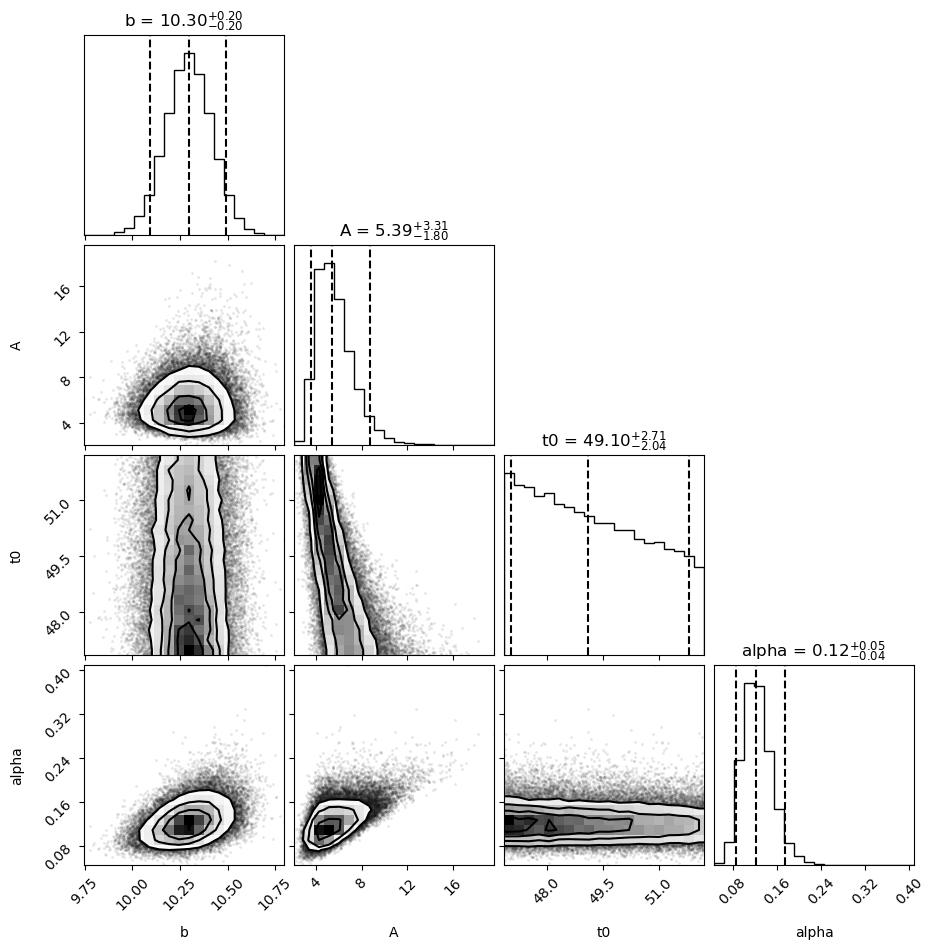

In [11]:
#L12 exercise 
#Lets do the same as before but with dynesty 


# Load the data
data = np.load('C:/Users/user/Desktop/astrostatistics_bicocca_2026/solutions/transient.npy')
t, flux, unc = data[:,0], data[:,1], data[:,2]

# model
def burst_model(t, b, A, t0, alpha):
    return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))

# likelihood function
def log_likelihood(theta, x, y, yerr):
    b, A, t0, alpha = theta
    model = burst_model(x, b, A, t0, alpha)
    return -0.5 * np.sum(((y - model) / yerr) ** 2)

# prior function
def log_prior(theta):
    b, A, t0, alpha = theta
    if 0 < b < 50 and 0 < A < 50 and 0 < t0 < 100 and np.exp(-5) < alpha < np.exp(5):
        return -np.log(alpha)
    return -np.inf

# posterior function
def log_posterior(theta, x, y, yerr):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr)

initial_guess = [10, 10, 50, 0.1]
n_samples = 10000
n_walkers = 50
n_dim = 4
pos = initial_guess + 1e-4 * np.random.randn(n_walkers, n_dim)

# emcee sampler
sampler_mcmc = emcee.EnsembleSampler(n_walkers, n_dim, log_posterior, args=(t, flux, unc))
sampler_mcmc.run_mcmc(pos, n_samples)

posterior_samples = sampler_mcmc.get_chain(discard=1000, thin=10, flat=True)

# corner plot
corner.corner(posterior_samples, labels=["b", "A", "t0", "alpha"], quantiles=[0.05, 0.5, 0.95], show_titles=True);

# median and 90% credible region
median = np.median(posterior_samples, axis=0)
cri = np.percentile(posterior_samples, [5, 95], axis=0)

print("Median:", median)
print("90% Credible Region:\n", cri)

In [12]:
from scipy import stats

logl_args = [t, flux, unc]
ndim = 4

def prior_transform_burst(u):
    b = stats.uniform.ppf(u[0], loc=0, scale=50)
    A = stats.uniform.ppf(u[1], loc=0, scale=50)
    t0 = stats.uniform.ppf(u[2], loc=0, scale=100)
    alpha = stats.loguniform.ppf(u[3], np.exp(-5), np.exp(5))
    return np.array([b, A, t0, alpha])

# Nested Sampling per il modello Burst
sampler = dynesty.NestedSampler(log_likelihood, prior_transform_burst, ndim, logl_args=logl_args, nlive=300)
sampler.run_nested()
sresults = sampler.results


C:\Users\user\AppData\Local\Temp\ipykernel_33592\461490501.py:11: RuntimeWarning: overflow encountered in exp
  return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))
C:\Users\user\AppData\Local\Temp\ipykernel_33592\461490501.py:11: RuntimeWarning: overflow encountered in multiply
  return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))
1062it [00:02, 265.30it/s, bound: 0 | nc: 50 | ncall: 10308 | eff(%): 10.303 | loglstar:   -inf < -172.931 <    inf | logz: -181.144 +/-  0.156 | dlogz: 122.025 >  0.309]   C:\Users\user\AppData\Local\Temp\ipykernel_33592\461490501.py:11: RuntimeWarning: overflow encountered in exp
  return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))
C:\Users\user\AppData\Local\Temp\ipykernel_33592\461490501.py:11: RuntimeWarning: overflow encountered in multiply
  return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))
1148it [00:02, 270.84it/s, bound: 2 | nc: 6 | ncall: 11083 | eff(%): 10.358 | loglstar:   -inf < -136.028 <    inf | logz

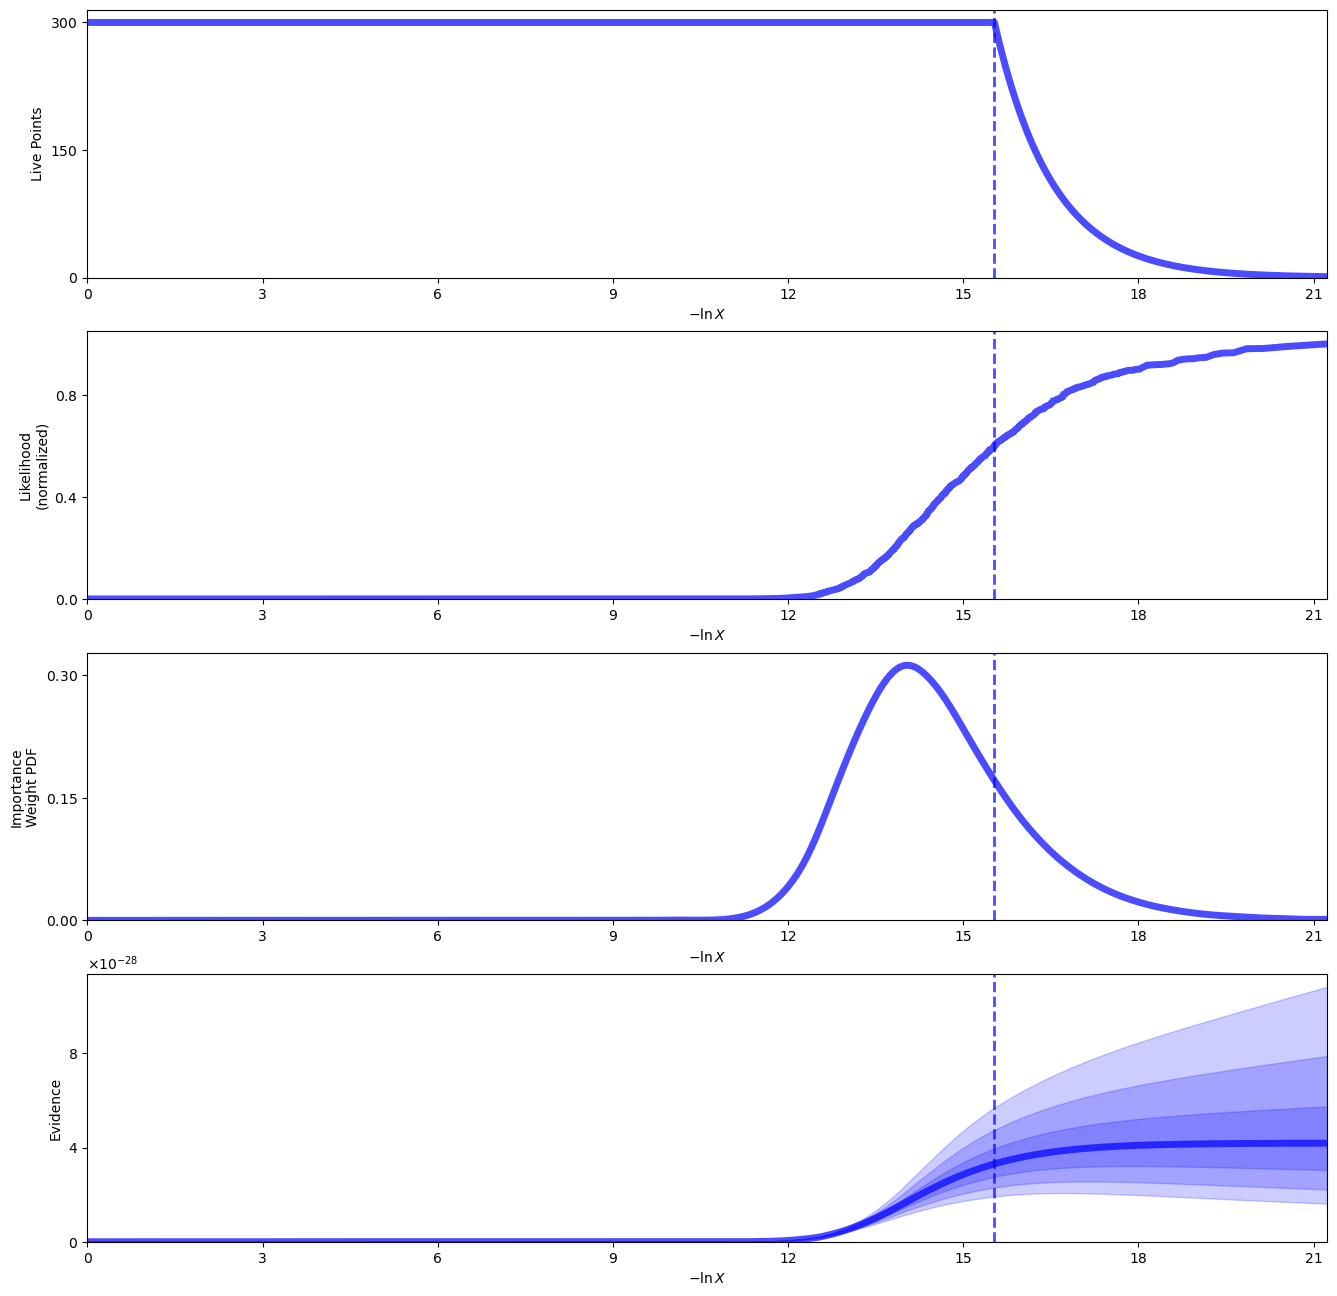

In [13]:
from dynesty import plotting as dyplot

# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults)

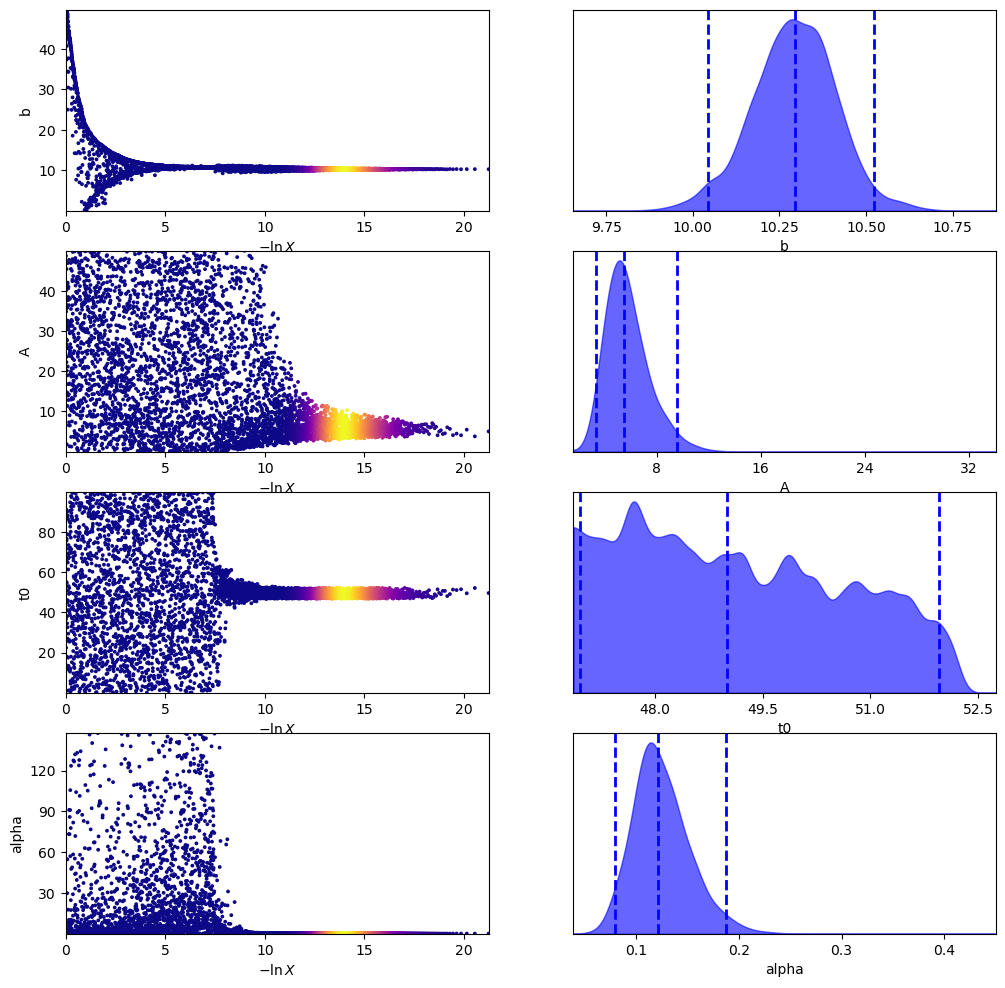

In [14]:
tfig, taxes = dyplot.traceplot(sresults, labels=["b", "A", "t0", "alpha"])

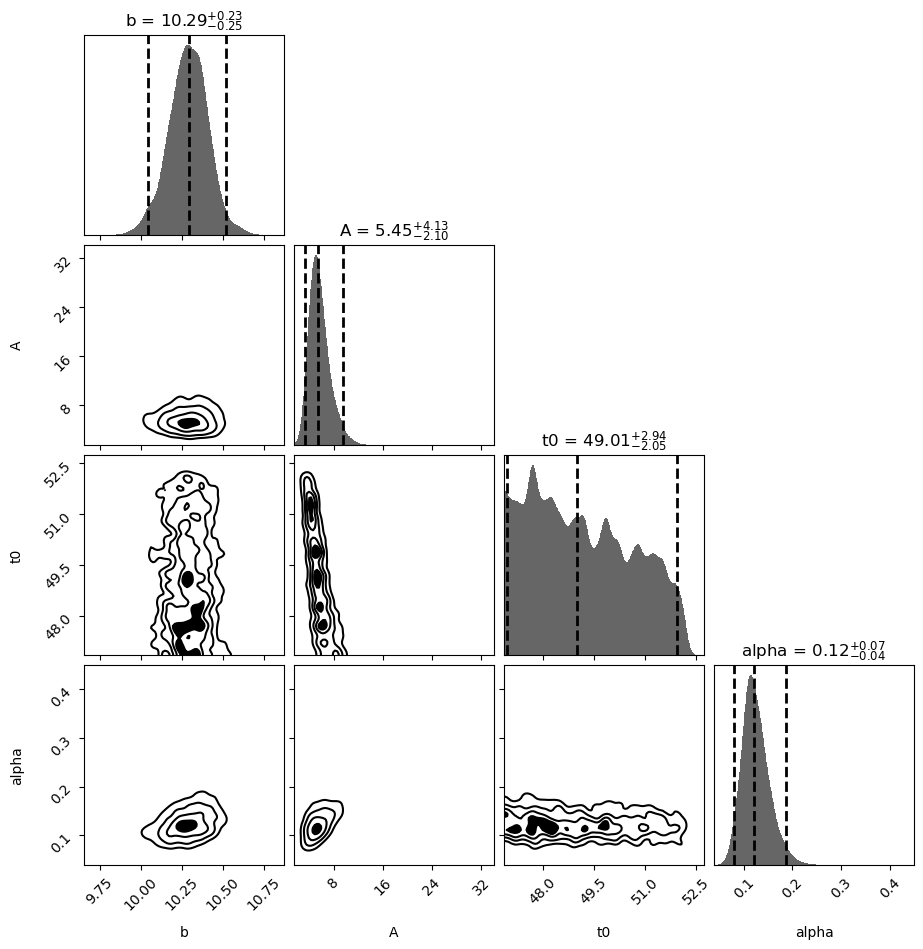

In [15]:
cfig, caxes = dyplot.cornerplot(sresults, labels=["b", "A", "t0", "alpha"], show_titles=True)

Summary
nlive: 300
niter: 4667
ncall: 88950
eff(%):  5.584
logz: -63.041 +/-  0.317
b = 10.294 (+0.186 / -0.207)  [90% CI: 10.088, 10.480]
A = 5.454 (+3.340 / -1.823)  [90% CI: 3.631, 8.794]
t0 = 49.005 (+2.710 / -1.930)  [90% CI: 47.075, 51.715]
alpha = 0.121 (+0.053 / -0.037)  [90% CI: 0.085, 0.175]


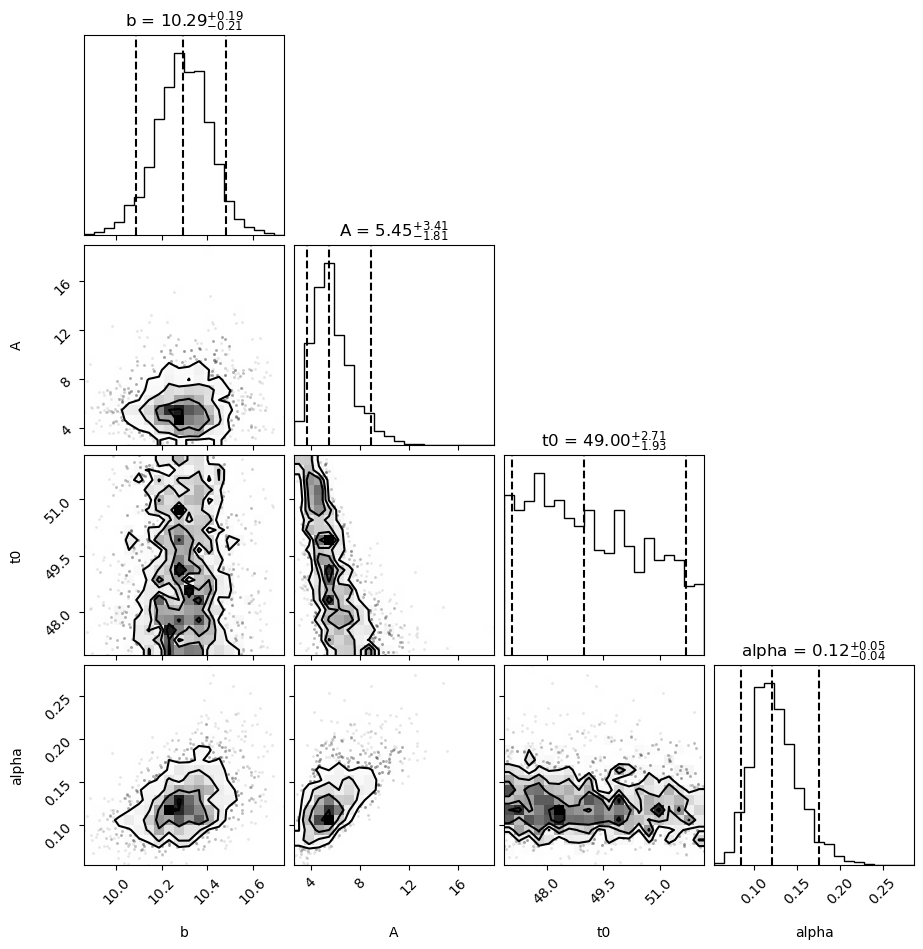

In [16]:
from dynesty import utils as dyfunc

# Estrazione dei campioni e dei pesi normalizzati per il modello Burst
samples_burst = sresults.samples
weights_burst = np.exp(sresults.logwt - sresults.logz[-1])

# Ricampionamento con pesi uguali per usare corner.corner
samples_equal_burst = dyfunc.resample_equal(samples_burst, weights_burst)

labels_burst = ["b", "A", "t0", "alpha"]
corner.corner(samples_equal_burst, labels=labels_burst, quantiles=[0.05, 0.5, 0.95], show_titles=True);

# Stampa del summary di dynesty (include logz e la sua incertezza)
sresults.summary()

# Calcolo di mediana e regione di credibilità al 90% (5% - 95%)
quantiles_burst = [dyfunc.quantile(samps, [0.05, 0.5, 0.95], weights=weights_burst)
                   for samps in samples_burst.T]
for name, q in zip(labels_burst, quantiles_burst):
    print(f"{name} = {q[1]:.3f} (+{q[2]-q[1]:.3f} / -{q[1]-q[0]:.3f})  [90% CI: {q[0]:.3f}, {q[2]:.3f}]")

In [17]:
# 7) Fit a Gaussian profile to the data using nested sampling

def gauss_model(t, b, A, t0, sigma_W):
    return b + A * np.exp(-0.5 * ((t - t0) / sigma_W) ** 2)

def log_likelihood_gauss(theta, x, y, yerr):
    b, A, t0, sigma_W = theta
    model = gauss_model(x, b, A, t0, sigma_W)
    return -0.5 * np.sum(((y - model) / yerr) ** 2)

def prior_transform_gauss(u):
    b = stats.uniform.ppf(u[0], loc=0, scale=50)
    A = stats.uniform.ppf(u[1], loc=0, scale=50)
    t0 = stats.uniform.ppf(u[2], loc=0, scale=100)
    # Prior log-uniforme per sigma_W in [exp(-2), exp(2)]
    sigma_W = stats.loguniform.ppf(u[3], np.exp(-2), np.exp(2))
    return np.array([b, A, t0, sigma_W])

# Nested Sampling per il modello Gaussiano
sampler_gauss = dynesty.NestedSampler(
    log_likelihood_gauss, prior_transform_gauss, ndim,
    logl_args=logl_args, nlive=300
)
sampler_gauss.run_nested()
sresults_gauss = sampler_gauss.results

2351it [00:20,  5.37it/s, bound: 101 | nc: 15 | ncall: 51075 | eff(%):  4.603 | loglstar:   -inf < -86.626 <    inf | logz: -94.223 +/-  0.148 | dlogz: 30.938 >  0.309]     c:\Users\user\anaconda3\Lib\site-packages\dynesty\bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
2559it [00:27, 23.43it/s, bound: 121 | nc: 491 | ncall: 70462 | eff(%):  3.632 | loglstar:   -inf < -82.183 <    inf | logz: -92.489 +/-  0.166 | dlogz: 28.720 >  0.309] c:\Users\user\anaconda3\Lib\site-packages\dynesty\bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using 

Summary
nlive: 300
niter: 4897
ncall: 101049
eff(%):  5.143
logz: -67.522 +/-  0.319


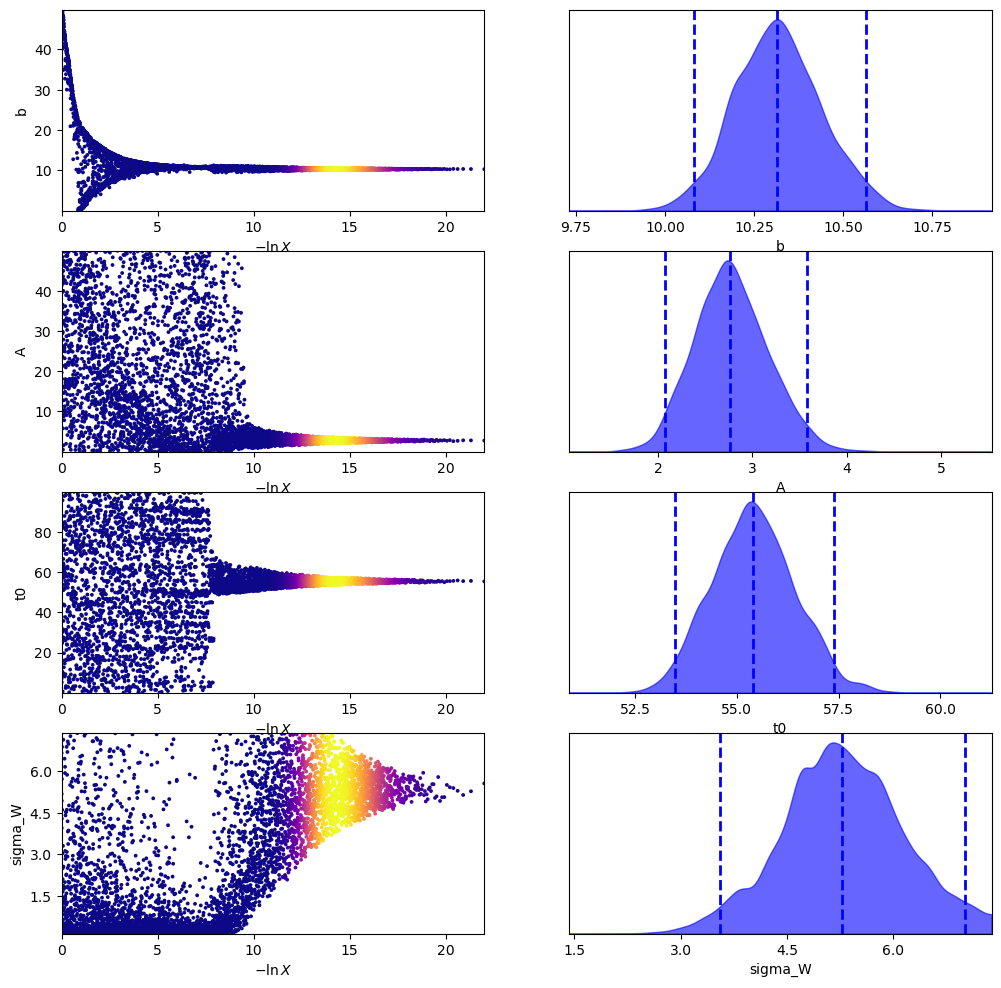

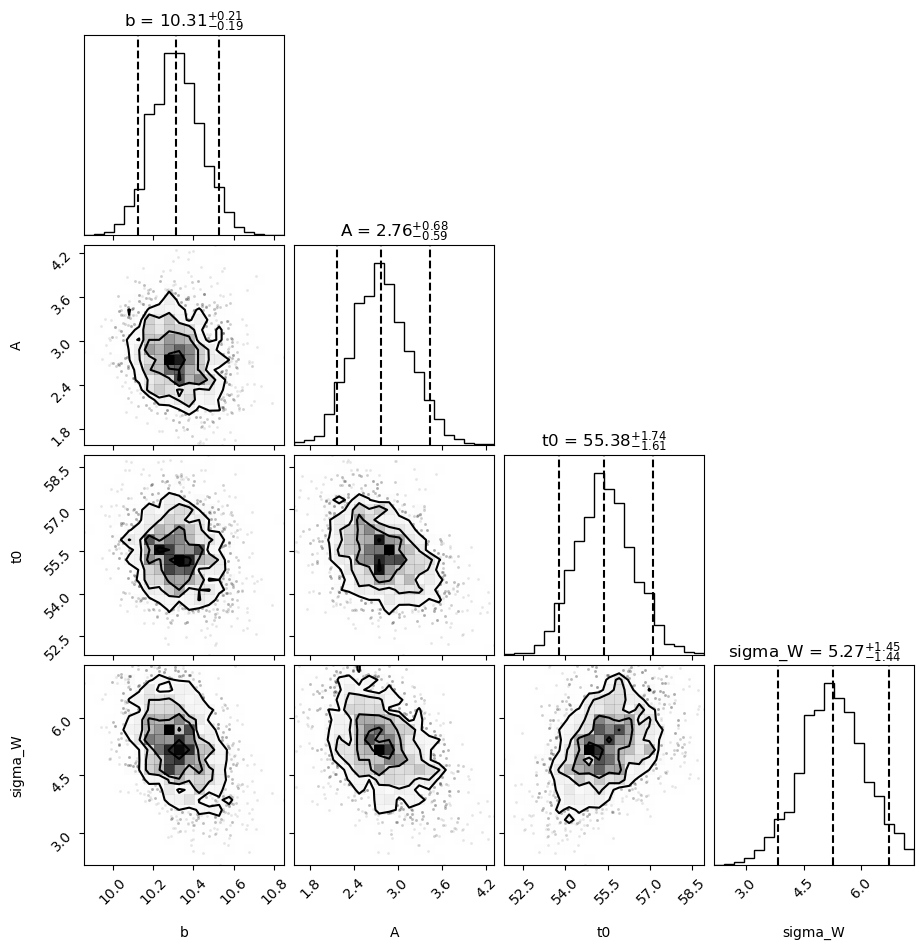

In [ ]:
# Traceplot Gaussiano
tfig_g, taxes_g = dyplot.traceplot(sresults_gauss, labels=["b", "A", "t0", "sigma_W"])

# Estrazione dei campioni ripesati e Corner Plot per il modello Gaussiano
samples_gauss = sresults_gauss.samples
weights_gauss = np.exp(sresults_gauss.logwt - sresults_gauss.logz[-1])
samples_equal_gauss = dyfunc.resample_equal(samples_gauss, weights_gauss)

labels_gauss = ["b", "A", "t0", "sigma_W"]
corner.corner(samples_equal_gauss, labels=labels_gauss, quantiles=[0.05, 0.5, 0.95], show_titles=True);

# Summary del modello Gaussiano
sresults_gauss.summary()

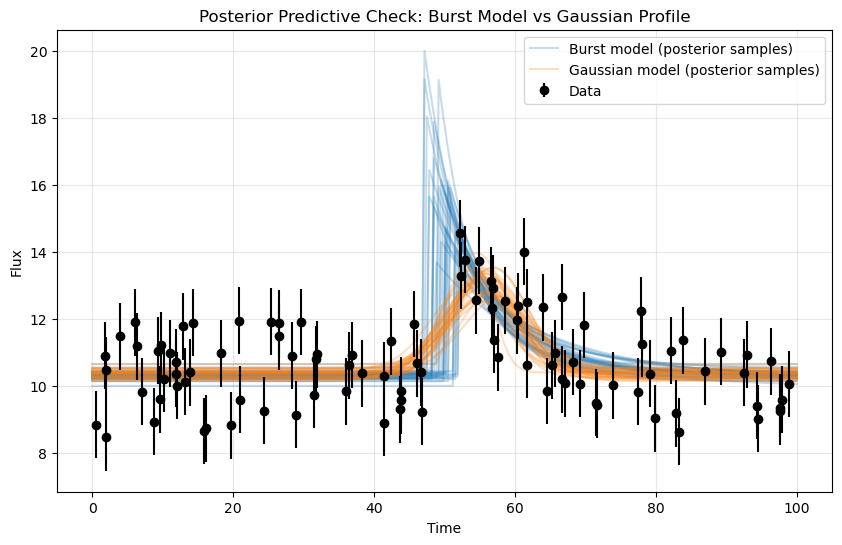

In [19]:
t_grid = np.linspace(0, 100, 300)

plt.figure(figsize=(10, 6))
plt.errorbar(t, flux, yerr=unc, fmt='o', color='black', label='Data', zorder=5)

# 30 curve dalla posterior del modello Burst
idx_burst = np.random.choice(len(samples_equal_burst), size=30, replace=False)
for i, theta_b in enumerate(samples_equal_burst[idx_burst]):
    lbl = 'Burst model (posterior samples)' if i == 0 else None
    plt.plot(t_grid, burst_model(t_grid, *theta_b), color='C0', alpha=0.25, label=lbl)

# 30 curve dalla posterior del modello Gaussiano
idx_gauss = np.random.choice(len(samples_equal_gauss), size=30, replace=False)
for i, theta_g in enumerate(samples_equal_gauss[idx_gauss]):
    lbl = 'Gaussian model (posterior samples)' if i == 0 else None
    plt.plot(t_grid, gauss_model(t_grid, *theta_g), color='C1', alpha=0.25, label=lbl)

plt.xlabel("Time")
plt.ylabel("Flux")
plt.title("Posterior Predictive Check: Burst Model vs Gaussian Profile")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
# 9) Compute the Bayesian evidence for both models, Bayes Factor, and interpret on Jeffreys' scale

logz_burst = sresults.logz[-1]
logzerr_burst = sresults.logzerr[-1]

logz_gauss = sresults_gauss.logz[-1]
logzerr_gauss = sresults_gauss.logzerr[-1]

# Log-Bayes Factor: ln(B_12) = ln(Z_burst) - ln(Z_gauss)
delta_logz = logz_burst - logz_gauss
delta_logz_err = np.sqrt(logzerr_burst**2 + logzerr_gauss**2)

# Bayes Factor: B_12 = exp(ln(Z_burst) - ln(Z_gauss))
bayes_factor = np.exp(delta_logz)
log10_bf = delta_logz / np.log(10)

print(f"Burst Model    : ln(Z) = {logz_burst:.3f} +/- {logzerr_burst:.3f}  (Z = {np.exp(logz_burst):.3e})")
print(f"Gaussian Model : ln(Z) = {logz_gauss:.3f} +/- {logzerr_gauss:.3f}  (Z = {np.exp(logz_gauss):.3e})")
print("-" * 65)
print(f"Delta ln(Z) = ln(B_burst/gauss) = {delta_logz:.3f} +/- {delta_logz_err:.3f}")
print(f"Bayes Factor B_burst/gauss      = {bayes_factor:.2f}")
print(f"log10(B_burst/gauss)            = {log10_bf:.2f}")
print("-" * 65)

# Interpretazione sulla Scala di Jeffreys
if log10_bf > 2:
    strength = "Decisive (Very strong) evidence in favor of the Burst model"
elif log10_bf > 1:
    strength = "Strong evidence in favor of the Burst model"
elif log10_bf > 0.5:
    strength = "Substantial evidence in favor of the Burst model"
elif log10_bf > 0:
    strength = "Inconclusive / Barely worth mentioning"
else:
    strength = "Gaussian model is favored"

print(f"Jeffreys' Scale Interpretation: {strength}")

Burst Model    : ln(Z) = -63.041 +/- 0.317  (Z = 4.184e-28)
Gaussian Model : ln(Z) = -67.522 +/- 0.319  (Z = 4.738e-30)
-----------------------------------------------------------------
Delta ln(Z) = ln(B_burst/gauss) = 4.481 +/- 0.450
Bayes Factor B_burst/gauss      = 88.31
log10(B_burst/gauss)            = 1.95
-----------------------------------------------------------------
Jeffreys' Scale Interpretation: Strong evidence in favor of the Burst model
